In [1]:
!pip install -Uqq fastbook
!pip install -Uqq kagglehub
%pip install -q "timm==0.6.13"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import fastbook
fastbook.setup_book()
from fastbook import *

In [3]:
import kagglehub
import os

# Replace with the exact strings found inside your downloaded kaggle.json
os.environ["KAGGLE_USERNAME"] = "nickswekosky"
os.environ["KAGGLE_KEY"] = "e407816df0cb2205b1bb53770f87092b"

In [4]:
comp = 'paddy-disease-classification'
file_path = kagglehub.competition_download(comp)

print("Path to competition files:", file_path)

Path to competition files: /root/.cache/kagglehub/competitions/paddy-disease-classification


In [5]:
import timm
from fastai.vision.all import *

In [6]:

set_seed(42)

from pathlib import Path
path = Path(file_path)
path.ls()

(#4) [Path('/root/.cache/kagglehub/competitions/paddy-disease-classification/train_images'),Path('/root/.cache/kagglehub/competitions/paddy-disease-classification/train.csv'),Path('/root/.cache/kagglehub/competitions/paddy-disease-classification/sample_submission.csv'),Path('/root/.cache/kagglehub/competitions/paddy-disease-classification/test_images')]

In [7]:
from sklearn.model_selection import train_test_split

PRACTICE_FRAC = 0.10

def practice_files(folder):
    files = sorted(get_image_files(folder))

    if PRACTICE_FRAC == 1.0:
        return files

    selected, _ = train_test_split(
        files,
        train_size=PRACTICE_FRAC,
        stratify=[f.parent.name for f in files],
        random_state=42,
    )

    return selected

# Part 1: First Steps
1. Overview: An initial end-to-end model and validation workflow.
2. Deliverable: A reproducible baseline, predictions, and a recorded validation result.
1. Link: https://www.kaggle.com/code/jhoward/first-steps-road-to-the-top-part-1


In [8]:
trn_path = path/'train_images'
files = get_image_files(trn_path)

(480, 640)


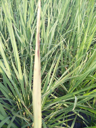

In [9]:
img = PILImage.create(files[0])
print(img.size)
img.to_thumb(128)

In [10]:
from fastcore.parallel import *

def f(o): return PILImage.create(o).size
sizes = parallel(f, files, n_workers=8)
pd.Series(sizes).value_counts()

(480, 640)    10403
(640, 480)        4
dtype: int64

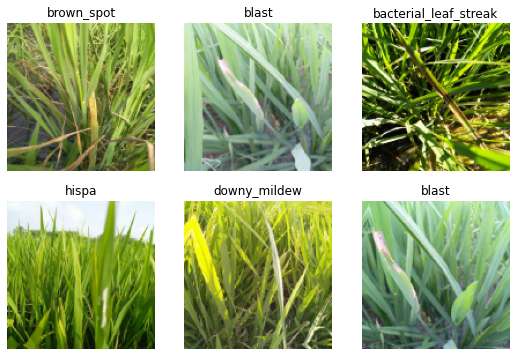

In [11]:
dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, seed=42,
    item_tfms=Resize(480, method='squish'),
    batch_tfms=aug_transforms(size=128, min_scale=0.75))

dls.show_batch(max_n=6)

In [15]:
learn = vision_learner(dls, 'resnet26d', metrics=error_rate, path='.').to_fp16()

Downloading:   0%|          | 0.00/64.2M [00:00<?, ?B/s]

SuggestedLRs(valley=0.0012022644514217973, slide=0.0063095735386013985)

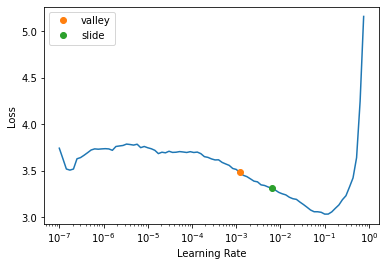

In [16]:
learn.lr_find(suggest_funcs=(valley, slide))

In [17]:
learn.fine_tune(3, 0.01)

epoch,train_loss,valid_loss,error_rate,time
0,1.797930,1.222638,0.399327,00:36


epoch,train_loss,valid_loss,error_rate,time
0,1.075408,0.804573,0.261893,00:43
1,0.791654,0.512854,0.164825,00:42
2,0.546795,0.433334,0.140798,00:42


In [12]:
tst_files = get_image_files(path/'test_images').sorted()
tst_dl = dls.test_dl(tst_files)

In [19]:
probs,_,idxs = learn.get_preds(dl=tst_dl, with_decoded=True)

In [20]:
mapping = dict(enumerate(dls.vocab))
results = pd.Series(idxs.numpy(), name="idxs").map(mapping)
results

0                       hispa
1                      normal
2                       hispa
3                       blast
4                       blast
                ...          
3464               dead_heart
3465                    hispa
3466                   normal
3467    bacterial_leaf_streak
3468               dead_heart
Name: idxs, Length: 3469, dtype: object

# Part 2: Small Models	Faster 
1. Overview: experimentation with small models.	
2. Deliverable: A reusable training function and a small experiment-results table.
3. Link: https://www.kaggle.com/code/jhoward/small-models-road-to-the-top-part-2/

In [8]:
trn_path = Path('sml')

In [ ]:
%%time
resize_images(
    path/'train_images',
    dest=trn_path,
    max_size=256,
    recurse=True,
    max_workers=0,
    progress=True,
    resume=False,
)

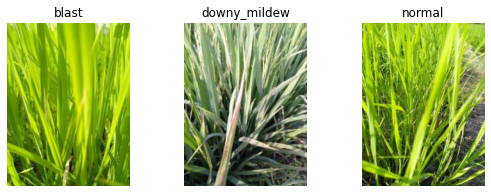

In [9]:
dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, seed=42,
    item_tfms=Resize((256,192)))

dls.show_batch(max_n=3)

In [13]:
def train(arch, item, batch, epochs=5):
    dls = ImageDataLoaders.from_path_func(
        trn_path,
        fnames=practice_files(trn_path),
        label_func=parent_label,
        valid_pct=0.2,
        seed=42,
        item_tfms=item,
        batch_tfms=batch,
        bs=64,
    )

    print(
        f"Training: {len(dls.train_ds):,} images | "
        f"Validation: {len(dls.valid_ds):,} images"
    )

    learn = vision_learner(
        dls, arch, metrics=error_rate
    ).to_fp16()

    learn.fine_tune(epochs, 0.01)
    return learn

In [11]:
learn = train('resnet26d', item=Resize(192),
              batch=aug_transforms(size=128, min_scale=0.75))

Training: 1,665 images | Validation: 416 images


Downloading:   0%|          | 0.00/64.2M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,error_rate,time
0,2.898114,2.679586,0.586538,00:10


epoch,train_loss,valid_loss,error_rate,time
0,1.955636,1.720993,0.495192,00:08
1,1.735516,1.571481,0.509615,00:08
2,1.542565,1.417304,0.475962,00:08
3,1.320495,1.245981,0.396635,00:08
4,1.159881,1.203136,0.387019,00:08


## Train a ConvNeXt model

In [14]:
arch = 'convnext_small_in22k'

## Squish vs Crop vs Pad

In [13]:
# Squish
learn = train(arch, item=Resize(192, method='squish'),
              batch=aug_transforms(size=128, min_scale=0.75))

Training: 1,665 images | Validation: 416 images


/usr/local/lib/python3.9/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


Downloading:   0%|          | 0.00/265M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,error_rate,time
0,2.323335,1.766980,0.459135,00:20


epoch,train_loss,valid_loss,error_rate,time
0,1.194743,0.899075,0.290865,00:33
1,1.029759,0.741977,0.218750,00:33
2,0.817817,0.677919,0.213942,00:33
3,0.626381,0.486894,0.139423,00:34
4,0.485701,0.462216,0.132212,00:34


In [14]:
# Crop
learn = train(arch, item=Resize(192),
              batch=aug_transforms(size=128, min_scale=0.75))

Training: 1,665 images | Validation: 416 images


/usr/local/lib/python3.9/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


epoch,train_loss,valid_loss,error_rate,time
0,2.287426,1.545998,0.384615,00:20


epoch,train_loss,valid_loss,error_rate,time
0,1.250826,0.858865,0.250000,00:33
1,1.070874,0.722065,0.240385,00:33
2,0.877245,0.718253,0.245192,00:33
3,0.681697,0.487113,0.153846,00:33
4,0.547829,0.468611,0.146635,00:33


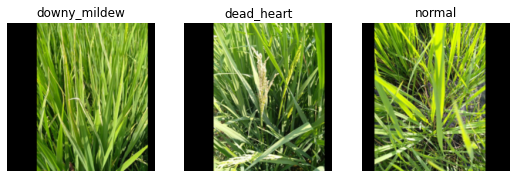

In [15]:
dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, seed=42,
    item_tfms=Resize(192, method=ResizeMethod.Pad, pad_mode=PadMode.Zeros))
dls.show_batch(max_n=3)

In [19]:
# Pad
learn = train(arch, item=Resize((256,192), method=ResizeMethod.Pad, pad_mode=PadMode.Zeros),
      batch=aug_transforms(size=(171,128), min_scale=0.75))

Training: 1,665 images | Validation: 416 images


/usr/local/lib/python3.9/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


Downloading:   0%|          | 0.00/265M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,error_rate,time
0,2.241518,1.206640,0.334135,00:11


epoch,train_loss,valid_loss,error_rate,time
0,1.205458,0.824066,0.281250,00:10
1,1.022515,0.710781,0.250000,00:09
2,0.844041,0.575384,0.182692,00:09
3,0.665790,0.455650,0.156250,00:09
4,0.514795,0.460394,0.144231,00:09


In [20]:
valid = learn.dls.valid
preds,targs = learn.get_preds(dl=valid)

In [21]:
error_rate(preds, targs)

TensorBase(0.1442)

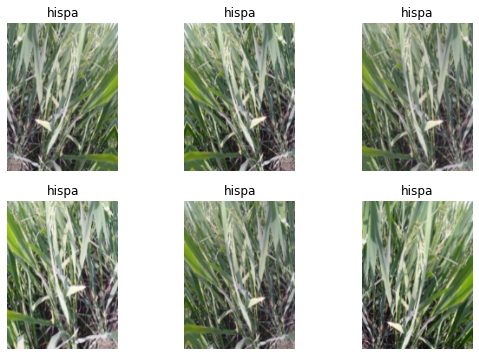

In [22]:
learn.dls.train.show_batch(max_n=6, unique=True)

## Test time augmentation¶


In [23]:
tta_preds,_ = learn.tta(dl=valid)

In [24]:
error_rate(tta_preds, targs)

TensorBase(0.1442)

In [13]:
trn_path = path/'train_images'

In [14]:
learn = train(arch, epochs=12,
              item=Resize((480, 360), method=ResizeMethod.Pad, pad_mode=PadMode.Zeros),
              batch=aug_transforms(size=(256,192), min_scale=0.75))

Training: 1,665 images | Validation: 416 images


/usr/local/lib/python3.9/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


Downloading:   0%|          | 0.00/265M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,error_rate,time
0,2.105093,1.447230,0.341346,00:40


epoch,train_loss,valid_loss,error_rate,time
0,1.037819,0.691733,0.235577,01:09
1,0.840418,0.628002,0.170673,01:08
2,0.733847,0.719886,0.211538,01:08
3,0.641708,0.658522,0.173077,01:08
4,0.508698,0.525602,0.134615,01:08
5,0.428769,0.564402,0.141827,01:08
6,0.342448,0.503871,0.129808,01:08
7,0.271959,0.433327,0.108173,01:08
8,0.218153,0.424491,0.115385,01:08
9,0.168230,0.403269,0.108173,01:08


In [15]:
tta_preds,targs = learn.tta(dl=learn.dls.valid)
error_rate(tta_preds, targs)

TensorBase(0.0841)

In [18]:
preds, _ = learn.tta(dl=learn.dls.test_dl(tst_files))

In [20]:
idxs = preds.argmax(dim=1)

In [21]:
vocab = np.array(learn.dls.vocab)
results = pd.Series(vocab[idxs], name="idxs")

# Part 3: Scaling Up	
1. Overview: GPU-memory constraints, gradient accumulation, and ensembles.	
2. Deliverable: A bounded comparison of a stronger model or ensemble—not every possible architecture.

In [16]:
df = pd.read_csv(path/'train.csv')
df.label.value_counts()

normal                      1764
blast                       1738
hispa                       1594
dead_heart                  1442
tungro                      1088
brown_spot                   965
downy_mildew                 620
bacterial_leaf_blight        479
bacterial_leaf_streak        380
bacterial_panicle_blight     337
Name: label, dtype: int64

In [17]:
trn_path = path/'train_images'/'bacterial_panicle_blight'

In [18]:
def train(arch, size, item=Resize(480, method='squish'), accum=1, finetune=True, epochs=12):
    dls = ImageDataLoaders.from_path_func(
        trn_path, 
        fnames=practice_files(trn_path),
        label_func=parent_label,
        valid_pct=0.2, 
        seed=42,
        item_tfms=item,
        batch_tfms=aug_transforms(size=size, min_scale=0.75), 
        bs=64//accum
    )
    
    print(
        f"Training: {len(dls.train_ds):,} images | "
        f"Validation: {len(dls.valid_ds):,} images"
    )
    
    cbs = GradientAccumulation(64) if accum else []
    learn = vision_learner(dls, arch, metrics=error_rate, cbs=cbs).to_fp16()
    if finetune:
        learn.fine_tune(epochs, 0.01)
        return learn.tta(dl=dls.test_dl(tst_files))
    else:
        learn.unfreeze()
        learn.fit_one_cycle(epochs, 0.01)
    return learn

In [19]:
df = pd.read_csv(path/'train.csv')
df.label.value_counts()

normal                      1764
blast                       1738
hispa                       1594
dead_heart                  1442
tungro                      1088
brown_spot                   965
downy_mildew                 620
bacterial_leaf_blight        479
bacterial_leaf_streak        380
bacterial_panicle_blight     337
Name: label, dtype: int64

In [20]:
import gc
def report_gpu():
    print(torch.cuda.list_gpu_processes())
    gc.collect()
    torch.cuda.empty_cache()

In [21]:
res = 640,480

In [22]:
models = {
    'convnext_large_in22k': {
        (Resize(res), (320,224)),
    }, 'vit_large_patch16_224': {
        (Resize(480, method='squish'), 224),
        (Resize(res), 224),
    }, 'swinv2_large_window12_192_22k': {
        (Resize(480, method='squish'), 192),
        (Resize(res), 192),
    }, 'swin_large_patch4_window7_224': {
        (Resize(res), 224),
    }
}

In [23]:
trn_path = path/'train_images'


In [24]:
tta_res = []

for arch,details in models.items():
    for item,size in details:
        print('---',arch)
        print(size)
        print(item.name)
        tta_res.append(train(arch, size, item=item, accum=2)) #, epochs=1))
        gc.collect()
        torch.cuda.empty_cache()

--- convnext_large_in22k
(320, 224)
Resize -- {'size': (480, 640), 'method': 'crop', 'pad_mode': 'reflection', 'resamples': (<Resampling.BILINEAR: 2>, <Resampling.NEAREST: 0>), 'p': 1.0}
Training: 832 images | Validation: 208 images


Downloading: "https://dl.fbaipublicfiles.com/convnext/convnext_large_22k_224.pth" to /root/.cache/torch/hub/checkpoints/convnext_large_22k_224.pth


epoch,train_loss,valid_loss,error_rate,time
0,2.347984,1.617402,0.341346,00:21


epoch,train_loss,valid_loss,error_rate,time
0,1.088978,0.890397,0.274038,00:23
1,0.894967,0.894660,0.245192,00:24
2,0.796711,0.788899,0.230769,00:23
3,0.682206,0.821859,0.221154,00:23
4,0.557623,0.681934,0.216346,00:23
5,0.444826,0.576152,0.158654,00:23
6,0.326590,0.547245,0.149038,00:23
7,0.264324,0.578354,0.168269,00:23
8,0.205677,0.541601,0.158654,00:23
9,0.143635,0.520349,0.149038,00:23


--- vit_large_patch16_224
224
Resize -- {'size': (480, 640), 'method': 'crop', 'pad_mode': 'reflection', 'resamples': (<Resampling.BILINEAR: 2>, <Resampling.NEAREST: 0>), 'p': 1.0}
Training: 832 images | Validation: 208 images


epoch,train_loss,valid_loss,error_rate,time
0,2.622092,1.821490,0.451923,00:14


... (11 outputs left out)

--- swin_large_patch4_window7_224
224
Resize -- {'size': (480, 640), 'method': 'crop', 'pad_mode': 'reflection', 'resamples': (<Resampling.BILINEAR: 2>, <Resampling.NEAREST: 0>), 'p': 1.0}
Training: 832 images | Validation: 208 images


Downloading: "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/swin_large_patch4_window7_224_22kto1k.pth" to /root/.cache/torch/hub/checkpoints/swin_large_patch4_window7_224_22kto1k.pth


epoch,train_loss,valid_loss,error_rate,time
0,2.512095,1.350506,0.418269,00:13


epoch,train_loss,valid_loss,error_rate,time
0,1.321139,0.883716,0.278846,00:14
1,1.052246,0.612348,0.192308,00:14
2,0.916448,0.524491,0.149038,00:14
3,0.774442,0.569377,0.163462,00:15
4,0.673853,0.595971,0.182692,00:15
5,0.521009,0.510921,0.129808,00:15
6,0.448737,0.510834,0.125000,00:15
7,0.351720,0.479651,0.120192,00:15
8,0.268833,0.448712,0.115385,00:15
9,0.207006,0.427440,0.100962,00:14


## Ensembling

In [25]:
tta_prs = first(zip(*tta_res))

In [26]:
tta_prs += tta_prs[1:3]

In [27]:
avg_pr = torch.stack(tta_prs).mean(0)
avg_pr.shape

torch.Size([3469, 10])

In [28]:
dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, item_tfms=Resize(480, method='squish'),
    batch_tfms=aug_transforms(size=224, min_scale=0.75))

In [29]:
idxs = avg_pr.argmax(dim=1)
vocab = np.array(dls.vocab)
vocab[idxs]

array(['hispa', 'normal', 'hispa', ..., 'normal', 'bacterial_leaf_streak', 'dead_heart'], dtype='<U24')

# Part 4: Multi-target	
1. Overview: Predicting disease and variety, with explicit losses and metrics.
2. Deliverable: A working two-target model whose outputs and loss you can explain.

In [8]:
trn_path = path/'train_images'

In [9]:
df = pd.read_csv(path/'train.csv', index_col='image_id')
df.head()

,label,variety,age
image_id,,,
100330.jpg,bacterial_leaf_blight,ADT45,45
100365.jpg,bacterial_leaf_blight,ADT45,45
100382.jpg,bacterial_leaf_blight,ADT45,45
100632.jpg,bacterial_leaf_blight,ADT45,45
101918.jpg,bacterial_leaf_blight,ADT45,45


In [10]:
def get_variety(p): return df.loc[p.name, 'variety']

In [11]:
dls = DataBlock(
    blocks=(ImageBlock,CategoryBlock,CategoryBlock),
    n_inp=1,
    get_items=get_image_files,
    get_y = [parent_label,get_variety],
    splitter=RandomSplitter(0.2, seed=42),
    item_tfms=Resize(192, method='squish'),
    batch_tfms=aug_transforms(size=128, min_scale=0.75)
).dataloaders(trn_path)

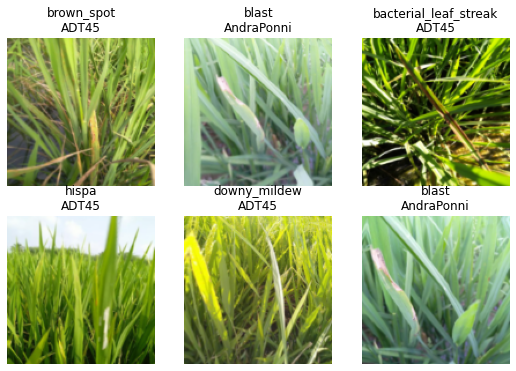

In [12]:
dls.show_batch(max_n=6)

In [13]:
def disease_err(inp,disease,variety): return error_rate(inp,disease)
def disease_loss(inp,disease,variety): return F.cross_entropy(inp,disease)

In [14]:
arch = 'convnext_small_in22k'
learn = vision_learner(dls, arch, loss_func=disease_loss, metrics=disease_err, n_out=10).to_fp16()
lr = 0.01

/usr/local/lib/python3.9/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name convnext_small_in22k to current convnext_small.fb_in22k.
  model = create_fn(


Downloading:   0%|          | 0.00/265M [00:00<?, ?B/s]

In [15]:
learn.fine_tune(5, lr)

epoch,train_loss,valid_loss,disease_err,time
0,1.279884,0.845763,0.241711,01:02


epoch,train_loss,valid_loss,disease_err,time
0,0.615401,0.435985,0.138395,01:37
1,0.472459,0.402758,0.111004,01:37
2,0.300332,0.238627,0.068717,01:37
3,0.187586,0.201633,0.057184,01:38
4,0.119463,0.169105,0.049495,01:37


In [16]:
learn = vision_learner(dls, arch, n_out=20).to_fp16()

In [17]:
def disease_loss(inp,disease,variety): return F.cross_entropy(inp[:,:10],disease)

In [18]:
def variety_loss(inp,disease,variety): return F.cross_entropy(inp[:,10:],variety)

In [19]:
def combine_loss(inp,disease,variety): return disease_loss(inp,disease,variety)+variety_loss(inp,disease,variety)

In [20]:
def disease_err(inp,disease,variety): return error_rate(inp[:,:10],disease)
def variety_err(inp,disease,variety): return error_rate(inp[:,10:],variety)

err_metrics = (disease_err,variety_err)

In [21]:
all_metrics = err_metrics+(disease_loss,variety_loss)

In [22]:
learn = vision_learner(dls, arch, loss_func=combine_loss, metrics=all_metrics, n_out=20).to_fp16()

In [23]:
learn.fine_tune(5, lr)

epoch,train_loss,valid_loss,disease_err,variety_err,disease_loss,variety_loss,time
0,2.284680,1.212197,0.260932,0.130226,0.803073,0.409124,00:59


epoch,train_loss,valid_loss,disease_err,variety_err,disease_loss,variety_loss,time
0,1.044034,0.706844,0.154733,0.070159,0.477786,0.229058,01:37
1,0.735145,0.434444,0.098030,0.034118,0.322929,0.111515,01:37
2,0.464073,0.285885,0.071120,0.025469,0.211040,0.074845,01:38
3,0.284164,0.225365,0.055262,0.014897,0.176616,0.048749,01:37
4,0.192371,0.206165,0.050457,0.013455,0.167411,0.038755,01:38
